In [4]:
import sys,warnings
warnings.filterwarnings("ignore")
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

sys.path.insert(0,str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display,Markdown

pd.set_option("display.max_columns",None,"display.width",200)
pd.set_option("display.float_format",lambda x:f"{x:,.3f}")
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams["figure.dpi"] = 100

from src import config as C


In [17]:
df_raw = pd.read_csv(C.RAW_PATH,dtype={"monthly_fee_tl":"object"})
display(df_raw.head(10))

,customer_id,age,region,device_type,plan,contract_type,tenure_months,monthly_usage_hours,monthly_fee_tl,discount_rate,payment_method,late_payments_6m,support_calls_6m,complaints_6m,satisfaction_score,churn
0,CUST100000,105.000,Central Anatolia,Desktop,Standard,Monthly,26,33.000,399.0,0.000,Credit Card,1,2,0,5.500,0
1,CUST100001,70.000,Mediterranean,Mobile,Standard,Annual,61,88.300,359.1,0.100,Bank Transfer,0,0,0,7.400,0
2,CUST100002,27.000,Aegean,Mobile,Premium,Monthly,61,50.000,599.0,0.000,Credit Card,0,2,0,5.400,0
3,CUST100003,32.000,Black Sea,Desktop,Premium,Monthly,22,58.000,599.0,0.000,Credit Card,1,0,0,6.000,1
4,CUST100004,47.000,Mediterranean,Mobile,Basic,Annual,41,70.100,224.1,0.100,Cash,1,0,0,7.900,0
5,CUST100005,41.000,Central Anatolia,Desktop,Basic,Monthly,69,42.800,211.65,0.150,Credit Card,1,0,0,6.800,0
6,CUST100006,60.000,Mediterranean,Tablet,Standard,Two-Year,58,32.400,319.2,0.200,Credit Card,0,1,0,5.800,0
7,CUST100007,50.000,Mediterranean,Desktop,Premium,Monthly,64,15.200,569.05,0.050,Credit Card,0,0,1,6.200,0
8,CUST100008,64.000,Black Sea,Mobile,Standard,Monthly,39,54.700,399.0,0.000,Credit Card,0,1,1,5.200,0
9,CUST100009,30.000,Black Sea,Mobile,Standard,Annual,13,33.500,399.0,0.000,E-Wallet,0,1,0,NaN,0


In [20]:
df_raw.tail()

,customer_id,age,region,device_type,plan,contract_type,tenure_months,monthly_usage_hours,monthly_fee_tl,discount_rate,payment_method,late_payments_6m,support_calls_6m,complaints_6m,satisfaction_score,churn
1815,CUST100312,46.000,Mediterranean,Tablet,Premium,Two-Year,32,60.100,539.1,0.100,Credit Card,0,1,0,10.000,0
1816,CUST101578,49.000,Marmara,Mobile,Standard,Two-Year,5,64.400,339.15,0.150,Credit Card,0,3,0,6.800,0
1817,CUST101441,NaN,Black Sea,Desktop,Standard,Monthly,13,68.300,399.0,0.000,Credit Card,0,1,0,5.800,0
1818,CUST100201,63.000,Mediterranean,Desktop,Standard,Annual,18,62.900,359.1,0.100,Credit Card,1,2,1,4.600,1
1819,CUST100920,NaN,Black Sea,Desktop,Premium,Annual,14,47.300,599.0,0.000,Credit Card,1,1,0,5.100,0


In [21]:
print("Satır,Sütun",df_raw.shape)

Satır,Sütun (1820, 16)


In [22]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1820 entries, 0 to 1819
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          1820 non-null   object 
 1   age                  1773 non-null   float64
 2   region               1788 non-null   object 
 3   device_type          1820 non-null   object 
 4   plan                 1820 non-null   object 
 5   contract_type        1820 non-null   object 
 6   tenure_months        1820 non-null   int64  
 7   monthly_usage_hours  1757 non-null   float64
 8   monthly_fee_tl       1797 non-null   object 
 9   discount_rate        1820 non-null   float64
 10  payment_method       1793 non-null   object 
 11  late_payments_6m     1820 non-null   int64  
 12  support_calls_6m     1820 non-null   int64  
 13  complaints_6m        1820 non-null   int64  
 14  satisfaction_score   1739 non-null   float64
 15  churn                1820 non-null   i

In [24]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,"1,773.000",46.671,17.130,-3.000,32.000,47.000,61.000,130.000
tenure_months,"1,820.000",37.103,20.567,1.000,19.000,38.000,55.000,72.000
monthly_usage_hours,"1,757.000",42.513,16.182,-5.000,31.600,42.100,53.100,180.000
discount_rate,"1,820.000",0.074,0.067,0.000,0.000,0.100,0.100,0.200
late_payments_6m,"1,820.000",0.546,0.746,0.000,0.000,0.000,1.000,4.000
support_calls_6m,"1,820.000",1.283,1.157,0.000,0.000,1.000,2.000,6.000
complaints_6m,"1,820.000",0.425,0.667,0.000,0.000,0.000,1.000,4.000
satisfaction_score,"1,739.000",6.150,1.763,0.000,5.000,6.200,7.400,11.000
churn,"1,820.000",0.083,0.276,0.000,0.000,0.000,0.000,1.000


In [27]:
df.columns

Index(['customer_id', 'age', 'region', 'device_type', 'plan', 'contract_type', 'tenure_months', 'monthly_usage_hours', 'monthly_fee_tl', 'discount_rate', 'payment_method', 'late_payments_6m',
       'support_calls_6m', 'complaints_6m', 'satisfaction_score', 'churn'],
      dtype='object')

In [32]:
cat_cols = ["region","device_type","plan","contract_type","payment_method"]
for col in cat_cols:
    print("\n==",col)
    display(df_raw[col].value_counts(dropna=False).to_frame("adet").T)


== region


region,Aegean,Black Sea,Central Anatolia,Eastern Anatolia,Mediterranean,Marmara,NaN,marmara
adet,318,300,296,293,291,283,32,7



== device_type


device_type,Mobile,Desktop,Tablet
adet,1072,585,163



== plan


plan,Basic,Standard,Premium,basic
adet,741,685,386,8



== contract_type


contract_type,Monthly,Annual,Two-Year,monthly
adet,988,558,267,7



== payment_method


payment_method,Credit Card,Bank Transfer,E-Wallet,Cash,NaN,credit card
adet,823,500,348,115,27,7


,eksik_adet,eksik_yuzde
satisfaction_score,81,4.451
monthly_usage_hours,63,3.462
age,47,2.582
region,32,1.758
payment_method,27,1.484
monthly_fee_tl,23,1.264


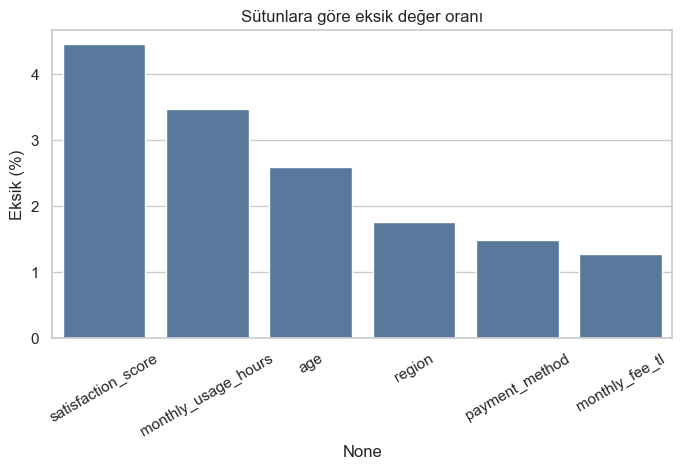

In [41]:
missing = pd.DataFrame({
    "eksik_adet":df_raw.isna().sum(),
    "eksik_yuzde":df_raw.isna().mean() * 100
})
missing=missing[missing.eksik_adet > 0].sort_values("eksik_yuzde",ascending=False)
display(missing)
fig,ax=plt.subplots(figsize=(8,4))
sns.barplot(x=missing.index,
           y=missing["eksik_yuzde"],color="#4c78a8",ax=ax)
ax.set_ylabel("Eksik (%)");
ax.set_title("Sütunlara göre eksik değer oranı")
plt.xticks(rotation=30)
plt.show()